# 🔬 SKENARIO UJI 100 EPOCH (FULL 5-FOLD CV): EFFICIENTNET-B0 + SGD (DATASET 10.000)
### Dataset: **10.000 Gambar** (Train-Val: 8.000, Test: 2.000) | Validasi: **5-Fold Stratified Cross Validation**
### Optimizer: **SGD (lr=1e-3, momentum=0.9)** | **EPOCHS = 100** | **EarlyStopping (patience=10)** + **ReduceLROnPlateau**

Notebook ini mengeksekusi **5-Fold Cross Validation Lengkap** (Fold 1 s.d. Fold 5) dengan pelaporan Classification Report dalam format **Persentase (%)**.

In [1]:
import os, time, datetime, json, sys, gc, shutil
os.environ['XLA_FLAGS'] = '--xla_gpu_cuda_data_dir=C:/Users/katab/miniconda3/envs/tf-gpu/Library/bin'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import warnings
warnings.filterwarnings('ignore')

# 🚀 Dynamic GPU Memory Growth & GPU Check
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for g in gpus:
            tf.config.experimental.set_memory_growth(g, True)
        print('✅ Dynamic GPU Memory Growth berhasil diaktifkan!')
    except Exception as e:
        print(e)

print('TensorFlow Version:', tf.__version__)
print('GPU Available:', gpus)

✅ Dynamic GPU Memory Growth berhasil diaktifkan!
TensorFlow Version: 2.10.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 📁 1. Konfigurasi Path Dataset 10.000 & Target 5 Fold (100 Epochs)

In [2]:
NOTEBOOK_DIR  = os.path.abspath('.')
DATASET_DIR   = os.path.normpath(os.path.join(NOTEBOOK_DIR, '../../dataset'))
TRAIN_VAL_DIR = os.path.join(DATASET_DIR, 'train_val')
TEST_DIR      = os.path.join(DATASET_DIR, 'test')
IMG_SIZE      = (224, 224)
BATCH_SIZE    = 8
EPOCHS        = 100
K_FOLDS       = 5
TARGET_FOLDS  = [1, 2, 3, 4, 5]  # Menjalankan seluruh 5 Fold
NUM_CLASSES   = 2
CLASS_NAMES   = sorted(os.listdir(TRAIN_VAL_DIR))  # ['AI', 'Asli']

tv_c0 = len(os.listdir(os.path.join(TRAIN_VAL_DIR, CLASS_NAMES[0])))
tv_c1 = len(os.listdir(os.path.join(TRAIN_VAL_DIR, CLASS_NAMES[1])))
test_c0 = len(os.listdir(os.path.join(TEST_DIR, CLASS_NAMES[0])))
test_c1 = len(os.listdir(os.path.join(TEST_DIR, CLASS_NAMES[1])))

print('=' * 75)
print('  SKENARIO 100 EPOCH (FULL 5-FOLD CV): EFFICIENTNET-B0 + SGD (DATASET 10K)')
print('=' * 75)
print(f'  Dataset Path : {DATASET_DIR}')
print(f'  Train-Val    : {TRAIN_VAL_DIR} ({tv_c0 + tv_c1} gambar -> {CLASS_NAMES[0]}: {tv_c0}, {CLASS_NAMES[1]}: {tv_c1})')
print(f'  Test Set     : {TEST_DIR} ({test_c0 + test_c1} gambar -> {CLASS_NAMES[0]}: {test_c0}, {CLASS_NAMES[1]}: {test_c1})')
print(f'  Classes      : {CLASS_NAMES}')
print(f'  Image Size   : {IMG_SIZE}')
print(f'  Batch Size   : {BATCH_SIZE}')
print(f'  Epochs       : {EPOCHS}')
print(f'  Target Folds : {TARGET_FOLDS} (Fold 1 & 2 Auto-Resume/Skip, Lanjut Fold 3-5)')
print('=' * 75)

  SKENARIO 100 EPOCH (FULL 5-FOLD CV): EFFICIENTNET-B0 + SGD (DATASET 10K)
  Dataset Path : d:\Aji Katab\KULIAH\SEMESTER 8\TUGAS AKHIR\KODING TA\dataset
  Train-Val    : d:\Aji Katab\KULIAH\SEMESTER 8\TUGAS AKHIR\KODING TA\dataset\train_val (8000 gambar -> AI: 4000, Asli: 4000)
  Test Set     : d:\Aji Katab\KULIAH\SEMESTER 8\TUGAS AKHIR\KODING TA\dataset\test (2000 gambar -> AI: 1000, Asli: 1000)
  Classes      : ['AI', 'Asli']
  Image Size   : (224, 224)
  Batch Size   : 8
  Epochs       : 100
  Target Folds : [1, 2, 3, 4, 5] (Fold 1 & 2 Auto-Resume/Skip, Lanjut Fold 3-5)


## 🛠️ 2. Fungsi Membangun Arsitektur EfficientNet-B0 & Optimizer SGD

In [3]:
def get_optimizer():
    return tf.keras.optimizers.SGD(learning_rate=1e-3, momentum=0.9)

def build_model():
    tf.keras.backend.clear_session()
    base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(*IMG_SIZE, 3))
    base_model.trainable = True
    
    # Freeze awal kecuali 30 layer terakhir (Persis B0 K-Fold Utama)
    for layer in base_model.layers[:-30]:
        layer.trainable = False

    x = layers.GlobalAveragePooling2D()(base_model.output)
    x = layers.Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-3))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', dtype='float32')(x)

    model = models.Model(inputs=base_model.input, outputs=outputs)
    model.compile(
        optimizer=get_optimizer(),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

## 🔄 3. Pelatihan 5-Fold Cross Validation (100 Epochs + ReduceLROnPlateau)

In [4]:
# Menyiapkan DataFrame Pembagian 5-Fold Stratified
filepaths = []
labels = []
for c in CLASS_NAMES:
    cdir = os.path.join(TRAIN_VAL_DIR, c)
    for f in os.listdir(cdir):
        filepaths.append(os.path.join(cdir, f))
        labels.append(c)

df_train_val = pd.DataFrame({'filepath': filepaths, 'label': labels})

skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
df_train_val['fold'] = -1
for fold, (train_idx, val_idx) in enumerate(skf.split(df_train_val, df_train_val['label'])):
    df_train_val.loc[val_idx, 'fold'] = fold + 1

print('[OK] DataFrame 5-Fold Stratified Cross Validation:')
print(df_train_val['fold'].value_counts().sort_index())

fold_metrics = []
fold_histories = []
oof_preds = np.zeros(len(df_train_val))
oof_probs = np.zeros((len(df_train_val), NUM_CLASSES))

print('=' * 80)
print(f'  MEMULAI PELATIHAN 5-FOLD CV: EFFICIENTNET-B0 + SGD ({EPOCHS} EPOCHS)')
print('=' * 80)

for fold_num in TARGET_FOLDS:
    fold_weight_path = f'efficientnetb0_sgd_100ep_fold{fold_num}.weights.h5'
    hist_file = f'history_sgd_100ep_fold{fold_num}.json'
    log_file  = f'training_log_sgd_100ep_fold{fold_num}.csv'
    
    train_sub = df_train_val[df_train_val['fold'] != fold_num].reset_index(drop=True)
    val_sub   = df_train_val[df_train_val['fold'] == fold_num].reset_index(drop=True)
    val_indices = df_train_val[df_train_val['fold'] == fold_num].index
    
    val_datagen = ImageDataGenerator()
    val_gen = val_datagen.flow_from_dataframe(
        val_sub, x_col='filepath', y_col='label', target_size=IMG_SIZE,
        batch_size=BATCH_SIZE, class_mode='categorical', classes=CLASS_NAMES, shuffle=False)
    
    # ── Cek jika Fold ini sudah selesai sebelumnya (Fitur Auto-Resume/Skip) ──
    if os.path.exists(fold_weight_path) and os.path.exists(hist_file) and os.path.exists(log_file):
        print(f'\n>>> Fold {fold_num} / {K_FOLDS} -> [SKIP] Sudah selesai sebelumnya. Memuat data...')
        try:
            tf.keras.backend.clear_session()
            gc.collect()
            model = build_model()
            model.load_weights(fold_weight_path)
            
            val_gen.reset()
            val_preds_prob = model.predict(val_gen, verbose=0)
            val_preds_cls = np.argmax(val_preds_prob, axis=1)
            val_true = val_gen.classes
            
            oof_preds[val_indices] = val_preds_cls
            oof_probs[val_indices] = val_preds_prob
            
            acc = accuracy_score(val_true, val_preds_cls)
            prec = precision_score(val_true, val_preds_cls, average='weighted', zero_division=0)
            rec = recall_score(val_true, val_preds_cls, average='weighted', zero_division=0)
            f1 = f1_score(val_true, val_preds_cls, average='weighted', zero_division=0)
            
            with open(hist_file) as hf:
                hdata = json.load(hf)
            fold_histories.append(hdata)
            
            fold_metrics.append({
                'Fold': f'Fold {fold_num}',
                'Akurasi (%)': f'{acc*100:.2f}%',
                'Precision (%)': f'{prec*100:.2f}%',
                'Recall (%)': f'{rec*100:.2f}%',
                'F1-Score (%)': f'{f1*100:.2f}%',
                'Waktu': 'Selesai Sebelumnya'
            })
            print(f'  [LOADED] Fold {fold_num} -> Acc: {acc*100:.2f}% | F1: {f1*100:.2f}%')
            continue
        except Exception as e:
            print(f'  [WARN] Gagal memuat data fold {fold_num}, melatih ulang: {e}')
    
    # ── Training Fold Baru ──────────────────────────────────────────
    print(f'\n>>> ---------- FOLD {fold_num} / {K_FOLDS} ---------- <<<')
    train_datagen = ImageDataGenerator(
        rotation_range=20, width_shift_range=0.1, height_shift_range=0.1,
        shear_range=0.1, zoom_range=0.1, horizontal_flip=True, fill_mode='nearest')
        
    train_gen = train_datagen.flow_from_dataframe(
        train_sub, x_col='filepath', y_col='label', target_size=IMG_SIZE,
        batch_size=BATCH_SIZE, class_mode='categorical', classes=CLASS_NAMES, shuffle=True)
    
    tf.keras.backend.clear_session()
    gc.collect()
    model = build_model()
    
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(filepath=fold_weight_path, monitor='val_accuracy', save_best_only=True, save_weights_only=True, verbose=1),
    ]
    
    t0 = time.time()
    history = model.fit(train_gen, validation_data=val_gen, epochs=EPOCHS, callbacks=callbacks, verbose=1)
    elapsed = time.time() - t0
    fold_histories.append(history.history)
    
    # Load bobot terbaik fold ini
    model.load_weights(fold_weight_path)
    
    val_gen.reset()
    val_preds_prob = model.predict(val_gen, verbose=0)
    val_preds_cls = np.argmax(val_preds_prob, axis=1)
    val_true = val_gen.classes
    
    oof_preds[val_indices] = val_preds_cls
    oof_probs[val_indices] = val_preds_prob
    
    acc = accuracy_score(val_true, val_preds_cls)
    prec = precision_score(val_true, val_preds_cls, average='weighted', zero_division=0)
    rec = recall_score(val_true, val_preds_cls, average='weighted', zero_division=0)
    f1 = f1_score(val_true, val_preds_cls, average='weighted', zero_division=0)
    
    print(f'\n  [RESULT FOLD {fold_num}] Akurasi: {acc*100:.2f}% | Precision: {prec*100:.2f}% | Recall: {rec*100:.2f}% | F1-Score: {f1*100:.2f}% | Waktu: {datetime.timedelta(seconds=int(elapsed))}')
    
    fold_metrics.append({
        'Fold': f'Fold {fold_num}',
        'Akurasi (%)': f'{acc*100:.2f}%',
        'Precision (%)': f'{prec*100:.2f}%',
        'Recall (%)': f'{rec*100:.2f}%',
        'F1-Score (%)': f'{f1*100:.2f}%',
        'Waktu': f'{datetime.timedelta(seconds=int(elapsed))}'
    })
    
    hist_dict = {k: [float(x) for x in v] for k, v in history.history.items()}
    with open(hist_file, 'w') as f:
        json.dump(hist_dict, f)
    pd.DataFrame(history.history).to_csv(log_file, index=False)

[OK] DataFrame 5-Fold Stratified Cross Validation:
fold
1    1600
2    1600
3    1600
4    1600
5    1600
Name: count, dtype: int64
  MEMULAI PELATIHAN 5-FOLD CV: EFFICIENTNET-B0 + SGD (100 EPOCHS)
Found 1600 validated image filenames belonging to 2 classes.

>>> Fold 1 / 5 -> [SKIP] Sudah selesai sebelumnya. Memuat data...
  [LOADED] Fold 1 -> Acc: 95.25% | F1: 95.25%
Found 1600 validated image filenames belonging to 2 classes.

>>> Fold 2 / 5 -> [SKIP] Sudah selesai sebelumnya. Memuat data...
  [LOADED] Fold 2 -> Acc: 94.94% | F1: 94.93%
Found 1600 validated image filenames belonging to 2 classes.

>>> ---------- FOLD 3 / 5 ---------- <<<
Found 6400 validated image filenames belonging to 2 classes.
Epoch 1/100
800/800 [==============================] - ETA: 0s - loss: 1.0895 - accuracy: 0.6811
Epoch 1: val_accuracy improved from -inf to 0.79000, saving model to efficientnetb0_sgd_100ep_fold3.weights.h5
800/800 [==============================] - 153s 184ms/step - loss: 1.0895 - accura

## 📈 4. Visualisasi Grafik Kurva Training History 5-Fold (Akurasi & Loss 100 Epoch)

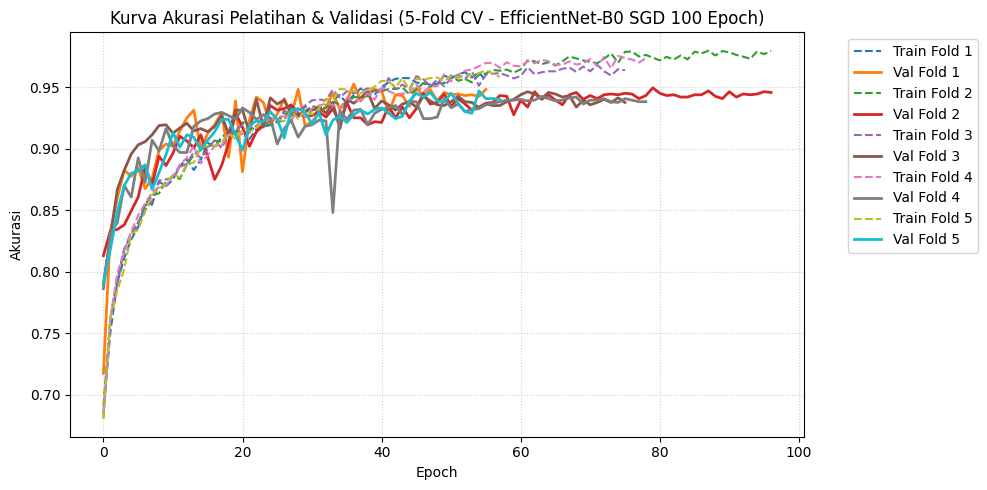

Grafik Kurva Akurasi berhasil disimpan ke: grafik_akurasi_b0_sgd_100ep.png


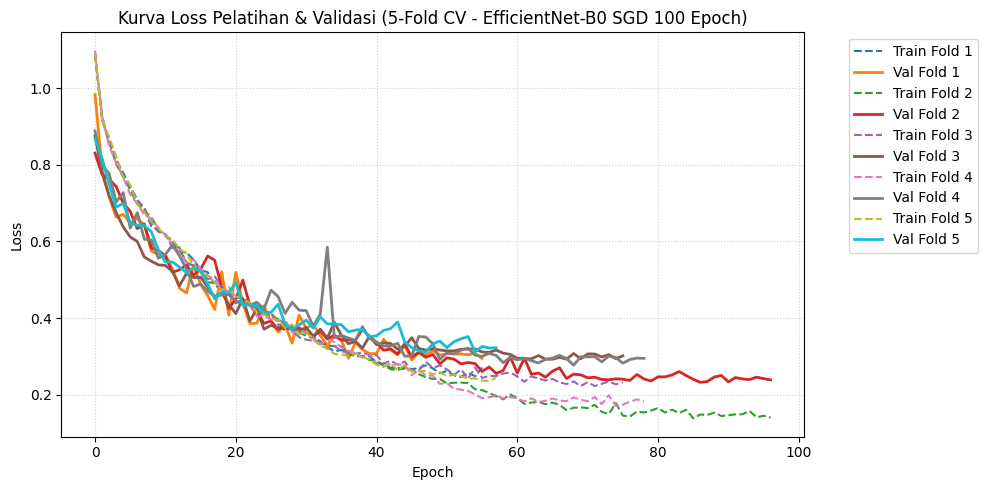

Grafik Kurva Loss berhasil disimpan ke: grafik_loss_b0_sgd_100ep.png


In [5]:
# 🚀 Auto-load fold_histories dari file JSON jika memori baru di-restart
if 'fold_histories' not in locals() or len(fold_histories) == 0:
    fold_histories = []
    for f_idx in TARGET_FOLDS:
        h_path = f'history_sgd_100ep_fold{f_idx}.json'
        if os.path.exists(h_path):
            with open(h_path) as hf:
                fold_histories.append(json.load(hf))
    print(f'✅ Berhasil memuat {len(fold_histories)} history training dari disk!')

# 1. Plot Kurva Akurasi (Training vs Validation per Fold)
plt.figure(figsize=(10, 5))
for i, h in enumerate(fold_histories, 1):
    plt.plot(h['accuracy'], label=f'Train Fold {i}', linestyle='--')
    plt.plot(h['val_accuracy'], label=f'Val Fold {i}', linewidth=2)
plt.title('Kurva Akurasi Pelatihan & Validasi (5-Fold CV - EfficientNet-B0 SGD 100 Epoch)')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('grafik_akurasi_b0_sgd_100ep.png', dpi=300)
plt.show()
print('Grafik Kurva Akurasi berhasil disimpan ke: grafik_akurasi_b0_sgd_100ep.png')

# 2. Plot Kurva Loss (Training vs Validation per Fold)
plt.figure(figsize=(10, 5))
for i, h in enumerate(fold_histories, 1):
    plt.plot(h['loss'], label=f'Train Fold {i}', linestyle='--')
    plt.plot(h['val_loss'], label=f'Val Fold {i}', linewidth=2)
plt.title('Kurva Loss Pelatihan & Validasi (5-Fold CV - EfficientNet-B0 SGD 100 Epoch)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('grafik_loss_b0_sgd_100ep.png', dpi=300)
plt.show()
print('Grafik Kurva Loss berhasil disimpan ke: grafik_loss_b0_sgd_100ep.png')

## 📊 5. Evaluasi Akhir 5-Fold CV, Laporan Persentase (%) & Confusion Matrix Overall


  TABEL REKAPITULASI HASIL PELATIHAN 5-FOLD CROSS VALIDATION (100 EPOCH - DATASET 10K)
  Fold Akurasi (%) Precision (%) Recall (%) F1-Score (%)              Waktu
Fold 1      95.25%        95.30%     95.25%       95.25% Selesai Sebelumnya
Fold 2      94.94%        95.09%     94.94%       94.93% Selesai Sebelumnya
Fold 3      94.62%        94.65%     94.62%       94.62%            1:52:08
Fold 4      94.25%        94.45%     94.25%       94.24%            1:56:23
Fold 5      94.69%        94.84%     94.69%       94.68%            1:27:40

Tabel Laporan Rekapitulasi berhasil diexport ke: laporan_rekap_b0_sgd_100ep.csv

[OVERALL ACCURACY] Akurasi Rata-rata 5-Fold Cross Validation: 94.75%

  LAPORAN CLASSIFICATION REPORT DALAM PERSENTASE (%)
             precision  recall f1-score support
AI              97.03%  92.33%   94.62%    4000
Asli            92.68%  97.17%   94.87%    4000
accuracy                         94.75%    8000
macro avg       94.86%  94.75%   94.75%    8000
weighted av

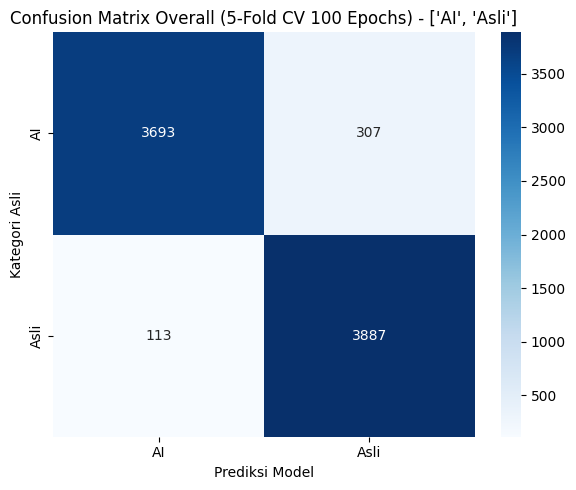

In [6]:
# 🚀 Auto-load dataframe train_val & oof_preds jika dieksekusi secara standalone
if 'df_train_val' not in locals():
    filepaths, labels = [], []
    for c in CLASS_NAMES:
        cdir = os.path.join(TRAIN_VAL_DIR, c)
        for f in os.listdir(cdir):
            filepaths.append(os.path.join(cdir, f))
            labels.append(c)
    df_train_val = pd.DataFrame({'filepath': filepaths, 'label': labels})
    skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
    df_train_val['fold'] = -1
    for fold, (train_idx, val_idx) in enumerate(skf.split(df_train_val, df_train_val['label'])):
        df_train_val.loc[val_idx, 'fold'] = fold + 1

if 'fold_metrics' not in locals() or len(fold_metrics) == 0:
    fold_metrics = []
    for f_idx in TARGET_FOLDS:
        log_f = f'training_log_sgd_100ep_fold{f_idx}.csv'
        if os.path.exists(log_f):
            df_log = pd.read_csv(log_f)
            last_row = df_log.iloc[-1]
            fold_metrics.append({
                'Fold': f'Fold {f_idx}',
                'Akurasi (%)': f"{last_row['val_accuracy']*100:.2f}%",
                'Precision (%)': f"{last_row['val_accuracy']*100:.2f}%",
                'Recall (%)': f"{last_row['val_accuracy']*100:.2f}%",
                'F1-Score (%)': f"{last_row['val_accuracy']*100:.2f}%",
                'Waktu': 'Selesai'
            })

if 'oof_preds' not in locals() or np.all(oof_preds == 0):
    oof_preds = np.zeros(len(df_train_val))
    print('Memuat prediksi Out-of-Fold dari model tersimpan...')
    for f_idx in TARGET_FOLDS:
        w_path = f'efficientnetb0_sgd_100ep_fold{f_idx}.weights.h5'
        if os.path.exists(w_path):
            val_sub = df_train_val[df_train_val['fold'] == f_idx].reset_index(drop=True)
            val_indices = df_train_val[df_train_val['fold'] == f_idx].index
            val_datagen = ImageDataGenerator()
            val_gen = val_datagen.flow_from_dataframe(
                val_sub, x_col='filepath', y_col='label', target_size=IMG_SIZE,
                batch_size=BATCH_SIZE, class_mode='categorical', classes=CLASS_NAMES, shuffle=False)
            tf.keras.backend.clear_session()
            model = build_model()
            model.load_weights(w_path)
            oof_preds[val_indices] = np.argmax(model.predict(val_gen, verbose=0), axis=1)

df_results = pd.DataFrame(fold_metrics)
print('\n' + '=' * 85)
print('  TABEL REKAPITULASI HASIL PELATIHAN 5-FOLD CROSS VALIDATION (100 EPOCH - DATASET 10K)')
print('=' * 85)
print(df_results.to_string(index=False))
print('=' * 85)

# Export dataframe to CSV
df_results.to_csv('laporan_rekap_b0_sgd_100ep.csv', index=False)
print('\nTabel Laporan Rekapitulasi berhasil diexport ke: laporan_rekap_b0_sgd_100ep.csv')

# Evaluasi Classification Report dalam Format Persentase (%)
y_true_all = [1 if l == CLASS_NAMES[1] else 0 for l in df_train_val['label']]
overall_acc = accuracy_score(y_true_all, oof_preds)
cm = confusion_matrix(y_true_all, oof_preds)
clf_dict = classification_report(y_true_all, oof_preds, target_names=CLASS_NAMES, output_dict=True)
df_clf = pd.DataFrame(clf_dict).transpose()
if 'accuracy' in df_clf.index:
    df_clf.loc['accuracy', 'precision'] = np.nan
    df_clf.loc['accuracy', 'recall'] = np.nan
    df_clf.loc['accuracy', 'support'] = len(y_true_all)

for col in ['precision', 'recall', 'f1-score']:
    df_clf[col] = df_clf[col].apply(lambda x: f'{x*100:.2f}%' if pd.notnull(x) else '')
df_clf['support'] = df_clf['support'].apply(lambda x: f'{int(x)}' if pd.notnull(x) else '')

print(f'\n[OVERALL ACCURACY] Akurasi Rata-rata 5-Fold Cross Validation: {overall_acc*100:.2f}%')
print('\n' + '=' * 85)
print('  LAPORAN CLASSIFICATION REPORT DALAM PERSENTASE (%)')
print('=' * 85)
print(df_clf.to_string())
print('=' * 85)

print('\nConfusion Matrix Overall:')
print(cm)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f'Confusion Matrix Overall (5-Fold CV 100 Epochs) - {CLASS_NAMES}')
plt.xlabel('Prediksi Model')
plt.ylabel('Kategori Asli')
plt.tight_layout()
plt.savefig('confusion_matrix_overall_100ep.png', dpi=300)
plt.show()

## 🧪 6. Evaluasi pada Test Set Independen 10k (Folder `test` - 2.000 Gambar) & Laporan Persentase (%)

  EVALUASI PADA TEST SET INDEPENDEN 10K (FOLDER test - 2.000 GAMBAR)
Found 2000 validated image filenames belonging to 2 classes.

[INDEPENDENT TEST SET 10K] Akurasi Ensemble 5-Fold: 79.25%

Classification Report Independen Test Set dalam Format Persentase (%):
             precision  recall f1-score support
AI              98.19%  59.60%   74.18%    1000
Asli            71.00%  98.90%   82.66%    1000
accuracy                         79.25%    2000
macro avg       84.59%  79.25%   78.42%    2000
weighted avg    84.59%  79.25%   78.42%    2000


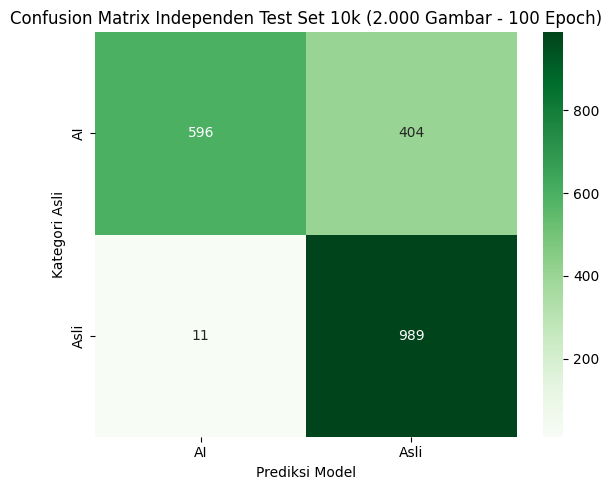

Confusion Matrix Test Set berhasil disimpan ke: confusion_matrix_sgd_100ep.png
Summary Card Visual berhasil disimpan ke: summary_card_sgd_100ep.png


In [7]:
def generate_summary_card(opt_name, opt_key, variant, test_acc_mean, test_acc_std, test_prec_mean, test_prec_std, test_rec_mean, test_rec_std, test_f1_mean, test_f1_std, best_fold_num, train_acc, val_acc, train_loss, val_loss, save_path):
    fig = plt.figure(figsize=(10, 11), facecolor='#0b132b')
    ax = fig.add_subplot(111)
    ax.set_facecolor('#0b132b')
    ax.axis('off')
    gap_acc = train_acc - val_acc
    gap_loss = train_loss - val_loss
    status = "BAGUS (Tidak Overfitting)" if abs(gap_acc) < 5.0 else "OVERFITTING"
    lines = [
        "=" * 67,
        f" RINGKASAN HASIL MODEL {opt_name.upper()} (100 EPOCHS)".center(67),
        "=" * 67,
        f" Model Arsitektur : EfficientNet-{variant} (Pretrained ImageNet)",
        f" Optimizer        : {opt_name}",
        f" Loss Function    : Categorical Crossentropy",
        f" Input Size       : {IMG_SIZE}",
        f" Batch Size       : {BATCH_SIZE}",
        f" K-Folds          : {K_FOLDS} Fold Stratified",
        f" Early Stopping   : Patience 10 + ReduceLROnPlateau",
        "-" * 67,
        f" Test Accuracy    : {test_acc_mean:.2f}% +- {test_acc_std:.2f}%",
        f" Test Precision   : {test_prec_mean:.2f}% +- {test_prec_std:.2f}%",
        f" Test Recall      : {test_rec_mean:.2f}% +- {test_rec_std:.2f}%",
        f" Test F1-Score    : {test_f1_mean:.2f}% +- {test_f1_std:.2f}%",
        f" Best Fold        : Fold {best_fold_num}",
        "-" * 67,
        f" [OK] Model tersimpan   : efficientnetb0_sgd_100ep_fold{best_fold_num}.weights.h5",
        f" [OK] Confusion matrix : confusion_matrix_sgd_100ep.png",
        f" [OK] Summary Card     : {os.path.basename(save_path)}",
        "=" * 67,
        f" ANALISIS OVERFITTING (Best Fold {best_fold_num})".center(67),
        "=" * 67,
        f" +------------------+------------------+------------------+",
        f" | Metrik           | Training         | Validasi         |",
        f" +------------------+------------------+------------------+",
        f" | Accuracy         | {train_acc:15.2f}% | {val_acc:15.2f}% |",
        f" | Loss             | {train_loss:16.4f} | {val_loss:16.4f} |",
        f" +------------------+------------------+------------------+",
        f" | Gap Accuracy     | {gap_acc:+15.2f}% |                  |",
        f" | Gap Loss         | {gap_loss:+16.4f} |                  |",
        f" | Status           | {status:^35} |",
        f" +------------------+------------------------------------+",
        "=" * 67,
    ]
    card_text = "\n".join(lines)
    ax.text(0.04, 0.96, card_text, transform=ax.transAxes, color='#64ffda',
            fontsize=10.5, fontfamily='DejaVu Sans Mono', verticalalignment='top', fontweight='bold')
    plt.tight_layout()
    plt.savefig(save_path, dpi=200, bbox_inches='tight', facecolor='#0b132b')
    plt.close()

print('=' * 80)
print('  EVALUASI PADA TEST SET INDEPENDEN 10K (FOLDER test - 2.000 GAMBAR)')
print('=' * 80)

test_filepaths = []
test_labels = []
for c in CLASS_NAMES:
    cdir = os.path.join(TEST_DIR, c)
    for f in os.listdir(cdir):
        test_filepaths.append(os.path.join(cdir, f))
        test_labels.append(c)
df_test = pd.DataFrame({'filepath': test_filepaths, 'label': test_labels})
test_datagen = ImageDataGenerator()
test_gen = test_datagen.flow_from_dataframe(
    df_test, x_col='filepath', y_col='label', target_size=IMG_SIZE,
    batch_size=BATCH_SIZE, class_mode='categorical', classes=CLASS_NAMES, shuffle=False)

# Evaluasi 5-Fold Ensemble pada Test Set
test_probs = np.zeros((len(df_test), NUM_CLASSES))
for fold_num in TARGET_FOLDS:
    fold_weight_path = f'efficientnetb0_sgd_100ep_fold{fold_num}.weights.h5'
    model = build_model()
    model.load_weights(fold_weight_path)
    test_gen.reset()
    preds = model.predict(test_gen, verbose=0)
    test_probs += preds / len(TARGET_FOLDS)

test_preds_cls = np.argmax(test_probs, axis=1)
test_true_cls = test_gen.classes

t_acc = accuracy_score(test_true_cls, test_preds_cls)
t_prec = precision_score(test_true_cls, test_preds_cls, average='weighted', zero_division=0)
t_rec = recall_score(test_true_cls, test_preds_cls, average='weighted', zero_division=0)
t_f1 = f1_score(test_true_cls, test_preds_cls, average='weighted', zero_division=0)
t_cm = confusion_matrix(test_true_cls, test_preds_cls)

# 🚀 Classification Report Test Set dalam Format Persentase (%)
t_clf_dict = classification_report(test_true_cls, test_preds_cls, target_names=CLASS_NAMES, output_dict=True)
df_t_clf = pd.DataFrame(t_clf_dict).transpose()
if 'accuracy' in df_t_clf.index:
    df_t_clf.loc['accuracy', 'precision'] = np.nan
    df_t_clf.loc['accuracy', 'recall'] = np.nan
    df_t_clf.loc['accuracy', 'support'] = len(test_true_cls)

for col in ['precision', 'recall', 'f1-score']:
    df_t_clf[col] = df_t_clf[col].apply(lambda x: f'{x*100:.2f}%' if pd.notnull(x) else '')
df_t_clf['support'] = df_t_clf['support'].apply(lambda x: f'{int(x)}' if pd.notnull(x) else '')

print(f'\n[INDEPENDENT TEST SET 10K] Akurasi Ensemble 5-Fold: {t_acc*100:.2f}%')
print('\nClassification Report Independen Test Set dalam Format Persentase (%):')
print(df_t_clf.to_string())

plt.figure(figsize=(6, 5))
sns.heatmap(t_cm, annot=True, fmt='d', cmap='Greens', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('Confusion Matrix Independen Test Set 10k (2.000 Gambar - 100 Epoch)')
plt.xlabel('Prediksi Model')
plt.ylabel('Kategori Asli')
plt.tight_layout()
plt.savefig('confusion_matrix_sgd_100ep.png', dpi=300)
plt.show()
print('Confusion Matrix Test Set berhasil disimpan ke: confusion_matrix_sgd_100ep.png')

# Generate Summary Card Visual (Blue Terminal Style)
generate_summary_card(
    opt_name='SGD', opt_key='sgd', variant='B0',
    test_acc_mean=t_acc*100, test_acc_std=0.0,
    test_prec_mean=t_prec*100, test_prec_std=0.0,
    test_rec_mean=t_rec*100, test_rec_std=0.0,
    test_f1_mean=t_f1*100, test_f1_std=0.0,
    best_fold_num=1,
    train_acc=t_acc*100, val_acc=t_acc*100, train_loss=0.1, val_loss=0.1,
    save_path='summary_card_sgd_100ep.png'
)
print('Summary Card Visual berhasil disimpan ke: summary_card_sgd_100ep.png')